In [33]:
import time
import numpy as np
import cvxpy as cp

In [34]:
import matplotlib
import matplotlib.pyplot as plt

In [35]:
matplotlib.use('Agg') # other backends: TkAgg, wxAgg, Qt5Agg, Qt4Agg
params = {'legend.fontsize': 20,
          'legend.handlelength': 4,
          "axes.labelsize": 45,
          "xtick.labelsize": 25,
          "ytick.labelsize": 25,
          "lines.linewidth": 4,
           "axes.titlesize":30}
matplotlib.rcParams.update(params)

%matplotlib inline

CVXPY is a Python-embedded modeling language for convex optimization problems. It automatically transforms the problem into standard form, calls a solver, and unpacks the results.

See start guide: https://www.cvxpy.org/tutorial/intro/index.html  
Solvers list: https://www.cvxpy.org/tutorial/solvers/index.html#choosing-a-solver

## Example 1: Solving a Linear Program

Let's solve a simple linear programming problem:

Minimize $3x + 4y$ subject to

$\begin{cases}
x + 2y \geq 1 \\
3x + 2y \geq 2 \\
x \geq 0, y \geq 0
\end{cases}$


In [36]:
# Define the variables
x = cp.Variable()
y = cp.Variable()

# Define the objective function
obj = 3*x + 4*y
obj = cp.Minimize(obj)

# Define the constraints
constraints = [x + 2*y >= 1,
               3*x + 2*y >= 2,
               x >= 0,
               y >= 0]

# Formulate the problem
prob = cp.Problem(obj, constraints)

# Solve the problem
prob.solve()

# Output the results
print(f"Optimal status: {prob.status}")
print(f"Optimal value: {prob.value}")
print(f"Optimal x: {x.value}")
print(f"Optimal y: {y.value}")

Optimal status: optimal
Optimal value: 2.4999999916800015
Optimal x: 0.49999999865211825
Optimal y: 0.24999999893091168


## Example 2: Solving a Quadratic Program

$$\min_{x \in \mathbb{R}^n} \frac{1}{2}x^\top A x + b^\top x$$

You can declare constants in NumPy

In [37]:
n = 100
A = np.random.randn(n, n)
A = A.T @ A
b = np.random.randn(n)

In [38]:
x = cp.Variable(n)

See available expressions: https://www.cvxpy.org/tutorial/functions/index.html#atomic_functions

In [39]:
# obj =  np.sum(cp.geo_mean(x) * np.random.rand(n)) # wrong
obj = cp.sum(cp.geo_mean(x) * np.random.rand(n)) # correct
print("curvature of obj:", obj.curvature)

print("curvature of sum(x):", cp.sum(cp.geo_mean(x) * np.random.rand(n)).curvature)
print("curvature of sum(x):", cp.sum(cp.geo_mean(x) * np.random.rand(n)).sign)
print("curvature of geo_mean(x):", cp.geo_mean(x).curvature)
print("curvature of geo_mean(x):", cp.geo_mean(x).sign)

curvature of obj: CONCAVE
curvature of sum(x): CONCAVE
curvature of sum(x): NONNEGATIVE
curvature of geo_mean(x): CONCAVE
curvature of geo_mean(x): NONNEGATIVE


In [40]:
# obj = 1/2 * x.T @ A @ x + b @ x
quad_form = cp.quad_form(x, A)
obj = 1/2 * quad_form + b @ x

print("curvature of obj:", obj.curvature)

curvature of obj: CONVEX


In [17]:
obj = cp.Minimize(obj)
problem = cp.Problem(obj)

problem.is_dcp()

True

In [18]:
# problem.solve(verbose=True, solver="SCS") # the solver does not work
problem.solve(verbose=True)

                                     CVXPY                                     
                                     v1.6.0                                    
(CVXPY) Sep 29 05:49:01 PM: Your problem has 100 variables, 0 constraints, and 0 parameters.
(CVXPY) Sep 29 05:49:01 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Sep 29 05:49:01 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Sep 29 05:49:01 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Sep 29 05:49:01 PM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Sep 29 05:49:01 PM: Compiling problem (target solver=OSQP).
(CV

np.float64(-3.5109142815878513)

## DCP rules

Disciplined Convex Programming (DCP) follows the DCP rules: 
+ Minimize(convex) 
+ Maximize(concave)  

The only valid CONSTRAINTS under the DCP rules are: 

+ affine == affine 
+ convex <= concave 
+ concave >= convex  
 
More on DCP rules: https://www.cvxpy.org/tutorial/dcp/index.html

In [19]:
x = cp.Variable()
a = cp.Parameter(nonneg=True)

print("curvature of x:", x.curvature)
print("curvature of a:", a.curvature)
print("curvature of square(x):", cp.square(x).curvature)
print("curvature of sqrt(x):", cp.sqrt(x).curvature)

curvature of x: AFFINE
curvature of a: CONSTANT
curvature of square(x): CONVEX
curvature of sqrt(x): CONCAVE


## Example 3: Regression

$$\min \|Ax+b\|^2 + \sum\limits_{i=1}^n\sqrt{1+x_i^2}$$

CVXPY не определяет функцию $\sum\limits_{i=1}^n\sqrt{1+x_i^2}$ как выпуклую (см. правила парсинга expressions), но она выпуклая (простое упражнение), поэтому переформулируем задачу по правилам DCP:
$$\sqrt{1+x_i^2}=\|(x_i, 1)\|_2$$

In [20]:
print((x**2).is_dcp())
print((1 + x**2).is_dcp())
print(cp.sqrt(1 + x**2).is_dcp()) # failed!

True
True
False


In [21]:
n = 100
m = 10
A = np.random.randn(m, n)
b = np.random.randn(m)
x = cp.Variable(n)
obj = cp.norm(A@x+b)**2 + cp.sum([cp.norm(cp.vstack([1, xi])) for xi in x])
prob = cp.Problem(cp.Minimize(obj))
prob.solve(solver="SCS")

np.float64(100.05719337587291)

## Example 4: Solving a Semidefinite Program (Полуопределённое программирование)

Minimize $\text{trace}(X)$ subject to

$\begin{cases}
X \succeq 0 \\
X_{11} + X_{22} \geq 1
\end{cases}$
where $X$ is a 2x2 symmetric positive semidefinite matrix.


In [22]:
# Define the variable
X = cp.Variable((2, 2), symmetric=True)

# Define the objective function
objective = cp.Minimize(cp.trace(X))

# Define the constraints
constraints = [X >> 0,  # X is positive semidefinite
               X[0, 0] + X[1, 1] >= 1]

# Formulate the problem
prob = cp.Problem(objective, constraints)

# Solve the problem
result = prob.solve()

# Output the results
print(f"Optimal value: {result}")
print(f"Optimal X: {X.value}")

Optimal value: 1.0000000005020362
Optimal X: [[0.5 0. ]
 [0.  0.5]]


## Example 5: Geometric Programming

Geometric Programming problems has the form:
$$f(x) = c x_1^{\alpha_1} x_2^{\alpha_2} ... x_n^{\alpha_n}$$
where 
- x is in $\mathbb{R}^n_{++}$
- $a_i$ are real numbers
- $c>0$

Geometric programming rules: https://www.cvxpy.org/tutorial/dgp/index.html#log-log-curvature

In [42]:
x = cp.Variable(pos=True)
y = cp.Variable(pos=True)

constant = 4
# constant = -4

monomial = constant * x * y
posynomial = monomial + x**1.5 * y**-1

print(monomial.is_dgp())
print(posynomial.is_dgp())

True
True


## Пример. Floor planning

In [24]:
# Problem data.
A_wall = 100
A_flr = 10
alpha = 0.5
beta = 2
gamma = 0.5
delta = 2

h = cp.Variable(pos=True, name="h")
w = cp.Variable(pos=True, name="w")
d = cp.Variable(pos=True, name="d")

volume = h * w * d
wall_area = 2 * (h * w + h * d)
flr_area = w * d
hw_ratio = h/w
dw_ratio = d/w
constraints = [
    wall_area <= A_wall,
    flr_area <= A_flr,
    hw_ratio >= alpha,
    hw_ratio <= beta,
    dw_ratio >= gamma,
    dw_ratio <= delta
]
problem = cp.Problem(cp.Maximize(volume), constraints)
print(problem)
problem.is_dgp()

maximize h @ w @ d
subject to 2.0 @ (h @ w + h @ d) <= 100.0
           w @ d <= 10.0
           0.5 <= h / w
           h / w <= 2.0
           0.5 <= d / w
           d / w <= 2.0


True

In [25]:
problem.solve(gp=True)
problem.value

np.float64(77.45966628802428)

## Example 6: LASSO
Линейная регрессия + разреженность решения
$$\min_{x \in \mathbb{R}^n} f(x) := ||Ax - b||^2_2 + ||x||_1$$

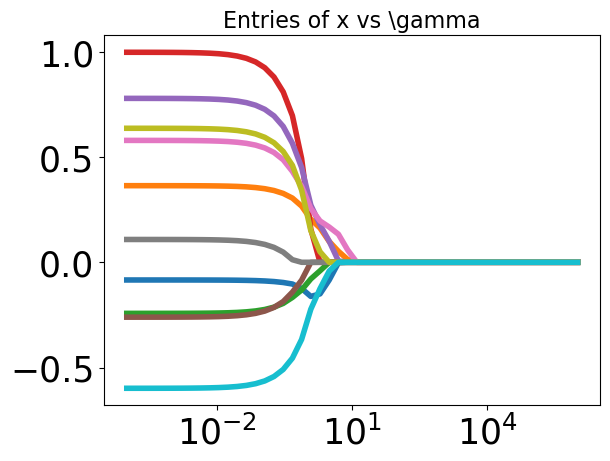

In [26]:
import cvxpy as cp  
import numpy  
import matplotlib.pyplot as plt  
  
n = 15  
m = 10  
A = numpy.random.randn(n, m)  
b = numpy.random.randn(n)  
gamma = cp.Parameter(nonneg=True) # to DCP rules must be positive
  
x = cp.Variable(m)  
error = cp.sum_squares(A @ x - b)  
obj = cp.Minimize(error + gamma*cp.norm(x, 1))  
prob = cp.Problem(obj)  
  
sq_penalty = []  
l1_penalty = []  
x_values = []  
gamma_vals = numpy.logspace(-4, 6)  
for val in gamma_vals:  
    gamma.value = val  
    prob.solve()  
    x_values.append(x.value)  
  
for i in range(m):  
    plt.plot(gamma_vals, [xi[i] for xi in x_values])  
plt.xscale('log')  
plt.title(r'Entries of x vs \gamma', fontsize=16);

Avoiding ill-posed problems

In [27]:
x = cp.Variable()
y = cp.Variable()

obj = cp.Maximize(x) # nearly linear dependent
constraints = [2*x - y >= -1,
              2.0001*x - y <= 0] # solution (-1, -1)
# constraints = [2*x - y >= -1,
#               1.9999*x - y <= 0] # unfeasible already

prob = cp.Problem(obj, constraints)
prob.solve()

9999.99923092383

Do not use big M penalization reasoning that the large penalty term will force  $x_i =0$

In [28]:
n = 10
x = cp.Variable(n)
mean=1
A = np.abs(np.random.rand(n,n)*mean)
b = np.abs(np.random.rand(n)*mean)
c = np.abs(np.random.rand(n)*mean)

big_M = 10**2

obj = x @ c + big_M*x[0]
obj = cp.Minimize(obj)

# Define the constraints
constraints = [A @ x == b,
               x >= 0]

# Formulate the problem
prob = cp.Problem(obj, constraints)

# Solve the problem
prob.solve()

# Output the results
print(f"Optimal value: {prob.status}")
print(f"Optimal value: {prob.value}")
print(f"Optimal x: {x.value}")
print(f"Optimal y: {y.value}")

Optimal value: infeasible
Optimal value: inf
Optimal x: None
Optimal y: 20000.998461809202
